# Apache SpamAssassin Spam Classification - Model Pipeline

Introductory TLDR goes here

## 1. Imports and Loading Packages

In [3]:
import matplotlib.pyplot as plt

from pathlib import Path
import seaborn as sns
import pandas as pd
import random

from utils import create_train_test_split, clean_emails, evaluate_model, plot_confusion_matrix

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier 
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.svm import SVC


seed = 42

## 2. Train Test Split

Since the train test split has already been made, we will skip this step

## 3. Building Data Pipeline

This involves feature engineering, and model building.

For feature engineering, we will choose to either remove the headers altogether or selectively mask the headers. Furthermore, we will also mask the URLs, numbers, etc.
- remove stop words - good for tf-idf

For model building we will use a list of models that is yet to be decided.

In [4]:
DATASPLIT_DIR = Path('./data_split')
RAW_DATA_DIR = Path('./raw_data')

X_train, y_train, X_test, y_test = create_train_test_split(raw_data_dir=RAW_DATA_DIR, data_split_dir=DATASPLIT_DIR, seed=seed)
len(X_train), len(X_test), len(y_train), len(y_test)

(7330, 1835, 7330, 1835)

In [5]:
X_train = clean_emails(emails = X_train, remove_headers=True)

## 4. Feature Engineering

Because the models cannot handle the text data, we will have to convert them into a matrix.

In [6]:
vectorizer = TfidfVectorizer(input='content', lowercase=True, stop_words='english', encoding='latin-1', max_features=10000)

## 5. Model Building

In [7]:
pipe = Pipeline([
    ("vectorizer", vectorizer),
    ("classifier", 'passthrough') # placeholder
])

### Model 1 - Logistic Regression

Logistic regression is a very good linear classification baseline. ```class_weight = 'balanced'``` multiples loss by the weight ($w_{class}$) $$w_{class} = \frac{total\_samples}{number\ of\ classes \times samples\ in\ the\ class}$$ 
This means for the minority class, the weight on the loss would be much more higher compared to the majority class, thus harshly updating the gradient in the case when the minority class prediction is wrong.

Evaluation Metrics for Logistic Regression:
Accuracy  : 0.9139
Precision : 0.9471
Recall    : 0.7098
F1 Score  : 0.8115
ROC-AUC   : 0.9868


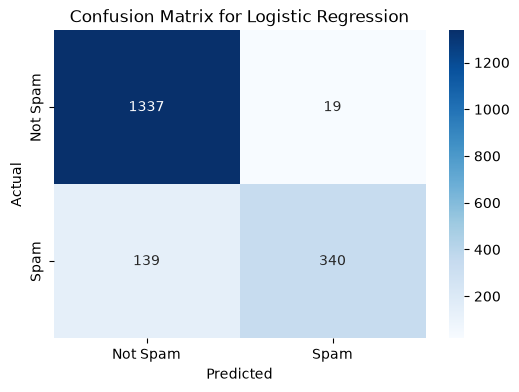

In [8]:
model_name = 'Logistic Regression'
lr = LogisticRegression(max_iter=2000, random_state=seed, class_weight='balanced')
lr_pipe = clone(pipe).set_params(
    classifier = lr
)

lr_pipe.fit(X_train, y_train)
pred_lr = lr_pipe.predict(X_test)
prob_lr = lr_pipe.predict_proba(X_test)[:, 1]

metrics_lr = evaluate_model(name=model_name, y_true=y_test, y_pred=pred_lr, y_prob=prob_lr)
plot_confusion_matrix(y_true = y_test, y_pred = pred_lr, title=f'Confusion Matrix for {model_name}')

### Model 2 - Decision Tree

A single decision tree is a good classifier but can be prone to overfitting (low bias and high variance) on an imbalanced dataset.

Evaluation Metrics for Decision Tree:
Accuracy  : 0.8877
Precision : 0.9361
Recall    : 0.6117
F1 Score  : 0.7399
ROC-AUC   : 0.7933


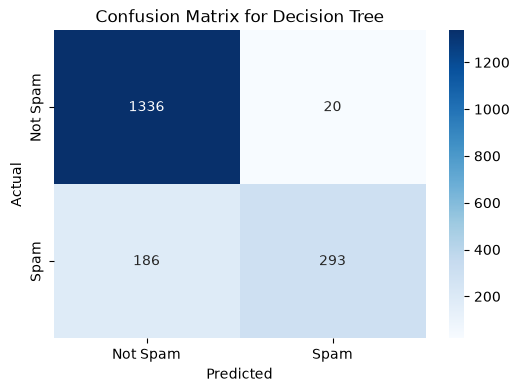

In [9]:
model_name = 'Decision Tree'
dt = DecisionTreeClassifier(random_state=seed, max_depth=8, class_weight='balanced')
dt_pipe = clone(pipe).set_params(
    classifier=dt
)

dt_pipe.fit(X_train, y_train)
pred_dt = dt_pipe.predict(X_test)
prob_dt = dt_pipe.predict_proba(X_test)[:, 1]

metrics_dt = evaluate_model(name=model_name, y_true=y_test, y_pred=pred_dt, y_prob=prob_dt)
plot_confusion_matrix(y_true = y_test, y_pred = pred_dt, title=f'Confusion Matrix for {model_name}')

### Model 3 - Random Forest

Random forest is an ensemble method where different decision trees vote on the output. This ensemble reduces the variance of the model and thus increase the bias. This essentially is an attempt to lower the overfitting in the decision of a single decision tree.

Evaluation Metrics for Random Forest:
Accuracy  : 0.9341
Precision : 0.9838
Recall    : 0.7599
F1 Score  : 0.8575
ROC-AUC   : 0.9949


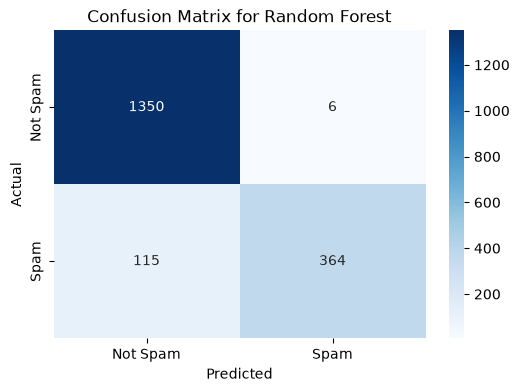

In [10]:
model_name = 'Random Forest'
rf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced", n_jobs=-1)
rf_pipe = clone(pipe).set_params(
    classifier=rf
)

rf_pipe.fit(X_train, y_train)
pred_rf = rf_pipe.predict(X_test)
prob_rf = rf_pipe.predict_proba(X_test)[:, 1]

metrics_rf = evaluate_model(name=model_name, y_true=y_test, y_pred=pred_rf, y_prob=prob_rf)
plot_confusion_matrix(y_true = y_test, y_pred = pred_rf, title=f'Confusion Matrix for {model_name}')

### Model 4: Multinomial Naive Bayes

Multinomial Naive Bayes is another model that works very well with tf-idf vectors in practice. However, this model is not equipped with handling class imbalance. Because of this reason, we will compute sample weights which amplifies the loss for the minority(spam) class.

Evaluation Metrics for Multinomial Naive Bayes:
Accuracy  : 0.8937
Precision : 0.8413
Recall    : 0.7307
F1 Score  : 0.7821
ROC-AUC   : 0.9727


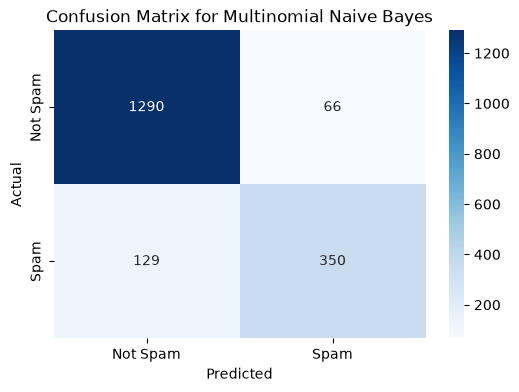

In [11]:
model_name = 'Multinomial Naive Bayes'
nb_multi = MultinomialNB()
nb_pipe = clone(pipe).set_params(
    classifier=nb_multi
)

sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)
nb_pipe.fit(X_train, y_train, classifier__sample_weight=sample_weights)
pred_nb = nb_pipe.predict(X_test)
prob_nb = nb_pipe.predict_proba(X_test)[:, 1]

metrics_nb = evaluate_model(name=model_name, y_true=y_test, y_pred=pred_nb, y_prob=prob_nb)
plot_confusion_matrix(y_true = y_test, y_pred = pred_nb, title=f'Confusion Matrix for {model_name}')

### Model 5: Xgboost

Xgboost is another great model where the loss is minimized by a sequence of decision trees that are trained to minimize the loss of the previous tree that was trained before it. As with naive bayes, this model doesn't have a class_weight feature, so we will use the sample_weight penalty to amplify the loss for the minority class.

Evaluation Metrics for Gradient Boosting:
Accuracy  : 0.9253
Precision : 0.9886
Recall    : 0.7223
F1 Score  : 0.8347
ROC-AUC   : 0.9925


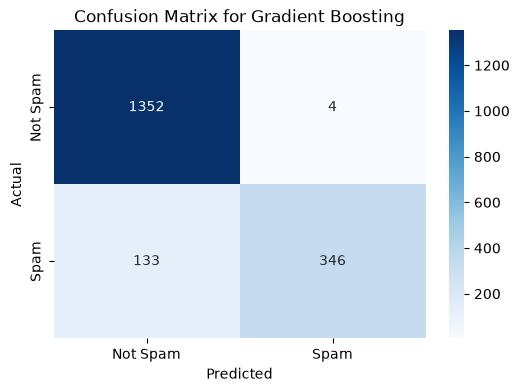

In [12]:
model_name = 'Gradient Boosting'
gb = GradientBoostingClassifier(n_estimators = 300, random_state=seed)
gb_pipe = clone(pipe).set_params(
    classifier=gb
)

gb_pipe.fit(X_train, y_train, classifier__sample_weight=sample_weights)
pred_gb = gb_pipe.predict(X_test)
prob_gb = gb_pipe.predict_proba(X_test)[:, 1]

metrics_gb = evaluate_model(name=model_name, y_true=y_test, y_pred=pred_gb, y_prob=prob_gb)
plot_confusion_matrix(y_true = y_test, y_pred = pred_gb, title=f'Confusion Matrix for {model_name}')

### Model 6: SVM

Support Vector machines are yet another powerful modeling tool which help in classification by classifying the data using decision boundaries.

Evaluation Metrics for SVM (RBF Kernel) calibrated:
Accuracy  : 0.9183
Precision : 0.9796
Recall    : 0.7015
F1 Score  : 0.8175
ROC-AUC   : 0.9943


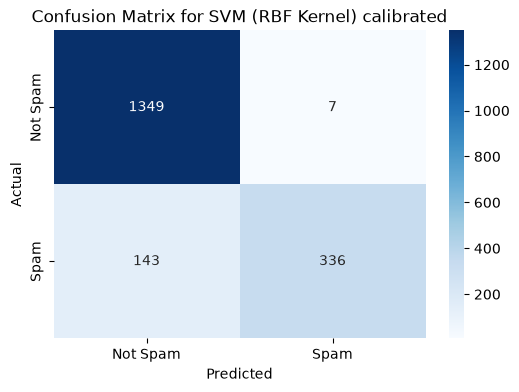

In [13]:
from sklearn.calibration import CalibratedClassifierCV

model_name = 'SVM (RBF Kernel) calibrated'

# svm_rbf = SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=seed) ## this is deprecated.
svm_rbf = SVC(kernel='rbf', random_state=seed, class_weight='balanced')
calibrated_svm = CalibratedClassifierCV(estimator=svm_rbf, method='sigmoid', cv=5)
svm_pipe = clone(pipe).set_params(
    classifier=calibrated_svm
)

svm_pipe.fit(X_train, y_train)
pred_svm = svm_pipe.predict(X_test)
prob_svm = svm_pipe.predict_proba(X_test)[:, 1]

metrics_svm = evaluate_model(name=model_name, y_true=y_test, y_pred=pred_svm, y_prob=prob_svm)
plot_confusion_matrix(y_true = y_test, y_pred = pred_svm, title=f'Confusion Matrix for {model_name}')

## 6. Model Comparison

We will collect all the metrics and visualize them to make comparison. Since, accuracy is misleading because of the class imbalance, we will sort this by F1 score.

In [14]:
collective_metrics = {
    'Logistic Regression': metrics_lr,
    'Decision Tree': metrics_dt,
    'Random Forest': metrics_rf,
    'Multinomial Naive Bayes': metrics_nb,
    'Gradient Boosting': metrics_gb,
    'SVM (RBF Kernel) calibrated': metrics_svm
}

results_df = pd.DataFrame(collective_metrics).T.sort_values(by='F1 Score', ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.93406,0.983784,0.759916,0.857479,0.994903
1,Gradient Boosting,0.925341,0.988571,0.722338,0.834741,0.992545
2,SVM (RBF Kernel) calibrated,0.918256,0.979592,0.701461,0.817518,0.994282
3,Logistic Regression,0.913896,0.947075,0.709812,0.811456,0.986787
4,Multinomial Naive Bayes,0.893733,0.841346,0.730689,0.782123,0.972711
5,Decision Tree,0.887738,0.936102,0.611691,0.739899,0.793284


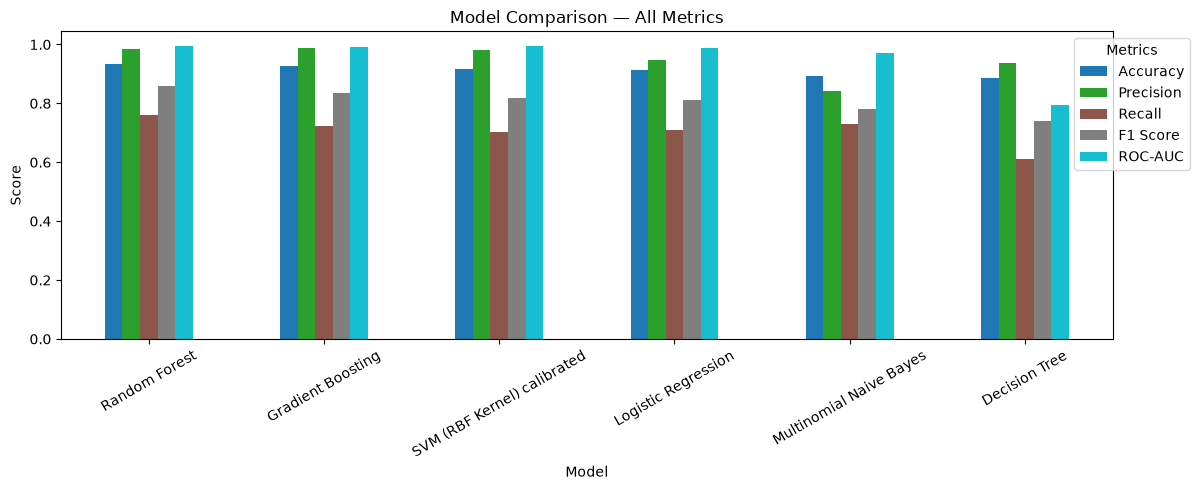

In [15]:
fig, ax = plt.subplots(figsize=(12, 5))
df_plot = results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]]
df_plot.plot(kind="bar", ax=ax, colormap="tab10")
ax.set_title("Model Comparison — All Metrics")
ax.set_ylabel("Score")
plt.xticks(rotation=30)
plt.legend(title="Metrics", bbox_to_anchor=(1.08, 1), loc='upper right')
plt.tight_layout()
plt.show()

## 7. 5-Folds Cross-Validation Models

Cross-validation allows us to compare models based on generalization without wasting a lot of training set.

In [16]:
models = {
    'Logistic Regression': lr_pipe,
    'Decision Tree': dt_pipe,
    'Random Forest': rf_pipe,
    'Multinomial Naive Bayes': nb_pipe,
    'Gradient Boosting': gb_pipe,
    'SVM (RBF Kernel) calibrated': svm_pipe
}

cv_scores = {}

print("Cross-Validation F1 Scores\n" + "-"*86)
for model_name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='f1', n_jobs=-1)
    cv_scores[model_name] = scores
    print(f"{model_name:28}: {scores}")
    print(f"Mean F1 Score {' ':>13} : {scores.mean():.4f} (+/- {scores.std():.4f})\n")

Cross-Validation F1 Scores
--------------------------------------------------------------------------------------
Logistic Regression         : [0.96382429 0.95785441 0.9726206  0.95865633 0.96907216]
Mean F1 Score               : 0.9644 (+/- 0.0058)

Decision Tree               : [0.88830486 0.89494163 0.89636608 0.89452603 0.8772846 ]
Mean F1 Score               : 0.8903 (+/- 0.0071)

Random Forest               : [0.97637795 0.97127937 0.9672346  0.9726206  0.97016861]
Mean F1 Score               : 0.9715 (+/- 0.0030)

Multinomial Naive Bayes     : [0.90488432 0.87593052 0.89795918 0.87674714 0.90745501]
Mean F1 Score               : 0.8926 (+/- 0.0136)

Gradient Boosting           : [0.96486486 0.97612732 0.95733333 0.9557047  0.96169089]
Mean F1 Score               : 0.9631 (+/- 0.0072)

SVM (RBF Kernel) calibrated : [0.98018494 0.9750983  0.9750983  0.98028909 0.97771953]
Mean F1 Score               : 0.9777 (+/- 0.0023)



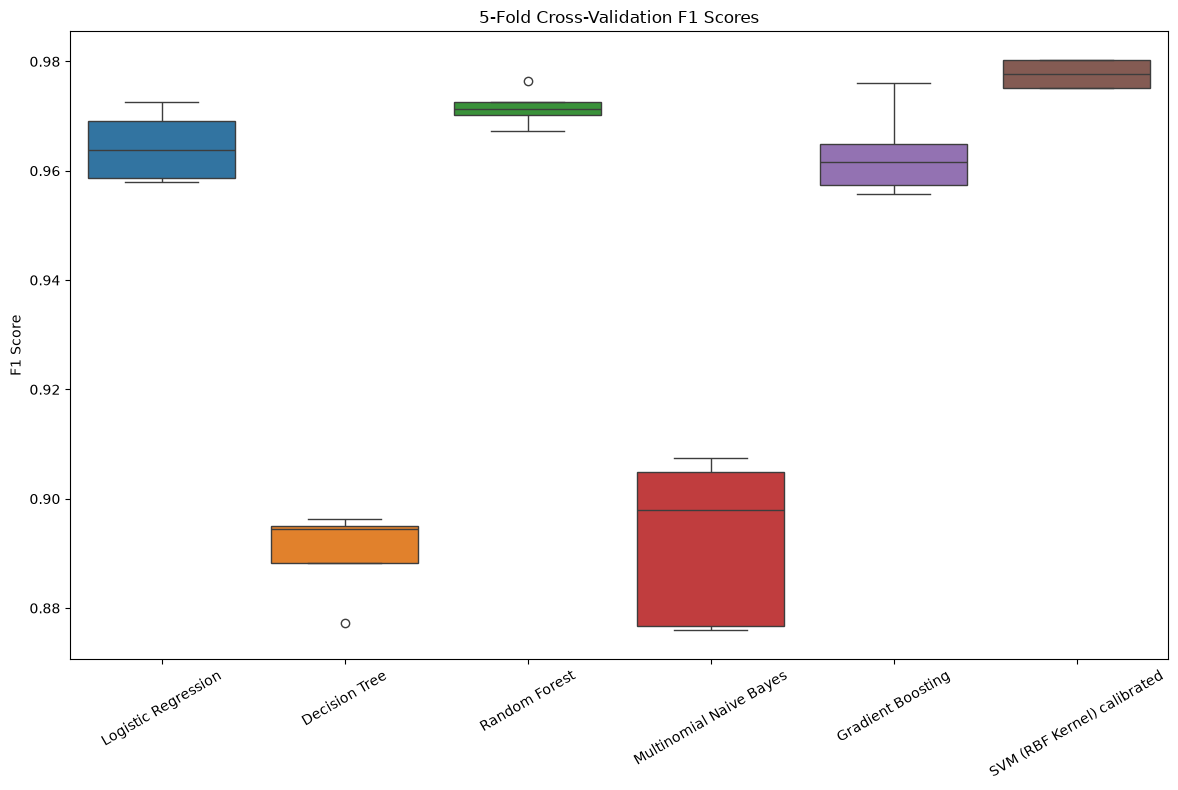

In [17]:
plt.figure(figsize=(12, 8))
sns.boxplot(data=pd.DataFrame(cv_scores))
plt.title("5-Fold Cross-Validation F1 Scores")
plt.xticks(rotation=30)
plt.ylabel("F1 Score")
plt.tight_layout()
plt.show()

## 8. Precision Recall and ROC

Because of the heavy data imbalance, the overall accuracy serves little purpose to our model evaluation. Suppose there is a 99:1 imbalance in the class, a model that always predicts the majority class is 99% accurate but completely fails at its job. Thus it is important to analyse the TP, FP, TN, FN. Precision-Recall curve and ROC curve help us do that.

It has to be noted that Precision Recall is more suitable for an imbalanced dataset compared to the ROC curve. 

A precision recall curve is defined by
$$ \text{Y-axis} \implies \text{Precision} = \frac{TP}{TP + FP}$$
$$\text {X-axis } \implies \text{Recall } = \frac{TP}{TP + FN} = \text{Sensitivity/TPR}$$

A ROC curve is defined by
$$\text {Y-axis } \implies \text{Recall } = \frac{TP}{TP + FN}$$
$$ \text{X-axis} \implies \text{FPR} = \frac{FP}{FP + TN}$$

When using ROC curves in imbalance datasets, a large nuimber of True Negatives can still keep the False Positive Rate very low, thus leading to misleading evaluation. On the other hand, because the PR curve focuses only on the positive class, it is very sensitive to poor performance on the positive class.

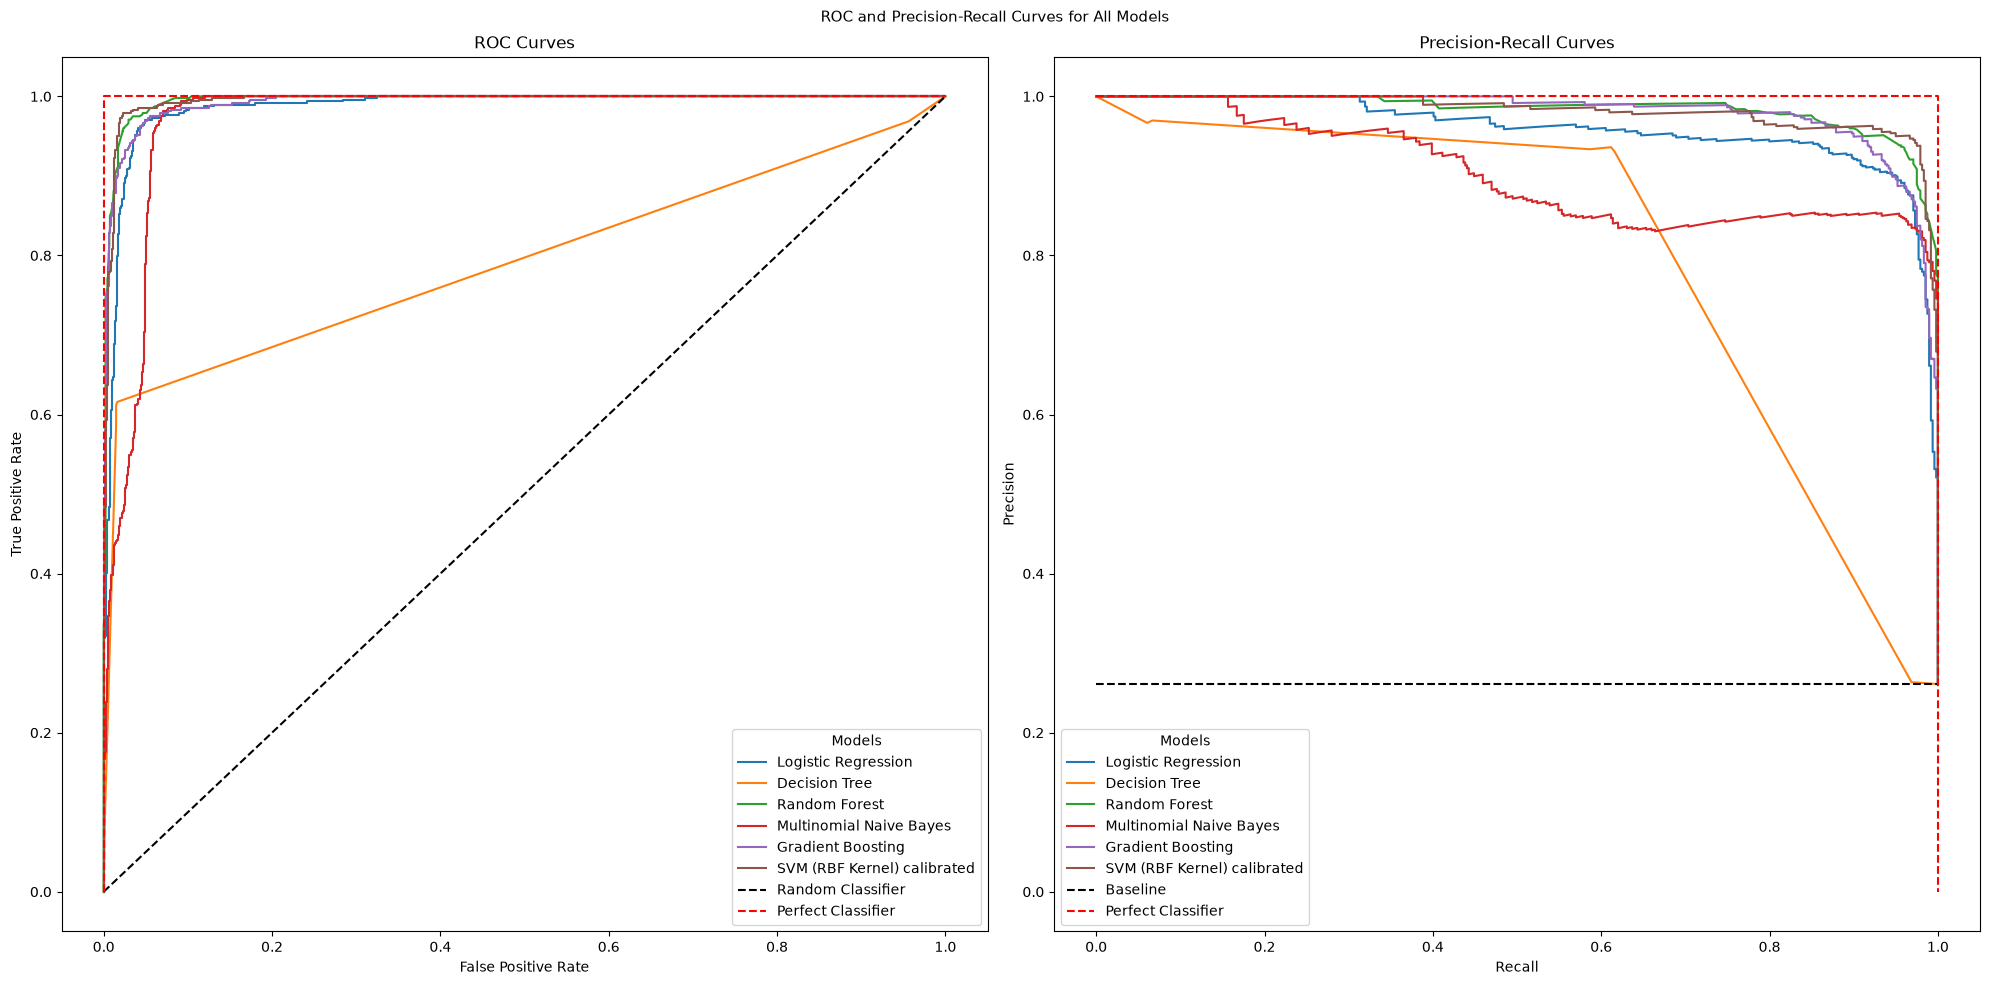

In [63]:
from sklearn.metrics import roc_curve, precision_recall_curve

model_proba = {
    'Logistic Regression': prob_lr,
    'Decision Tree': prob_dt,
    'Random Forest': prob_rf,
    'Multinomial Naive Bayes': prob_nb,
    'Gradient Boosting': prob_gb,
    'SVM (RBF Kernel) calibrated': prob_svm
}

fig, ax = plt.subplots(1, 2, figsize=(20, 10))

# ROC Curves
for model, prob in model_proba.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax[0].plot(fpr, tpr, label=f"{model}")
ax[0].plot([0, 1], [0, 1], 'k--', label='Random Classifier')
ax[0].plot([0, 0, 1], [0, 1, 1], 'r--', label='Perfect Classifier')
ax[0].set_title("ROC Curves")
ax[0].set_xlabel("False Positive Rate")
ax[0].set_ylabel("True Positive Rate")
ax[0].legend(title="Models", loc='lower right')

# Precision-Recall Curves
for model, prob in model_proba.items():
    precision, recall, _ = precision_recall_curve(y_test, prob)
    ax[1].plot(recall, precision, label=f"{model}")
baseline_pr = sum(y_test) / len(y_test)
ax[1].plot([0, 1], [baseline_pr, baseline_pr], 'k--', label='Baseline')
ax[1].plot([0, 1, 1], [1, 1, 0], 'r--', label='Perfect Classifier')
ax[1].set_title("Precision-Recall Curves")
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
ax[1].legend(title="Models", loc='lower left')

fig.suptitle("ROC and Precision-Recall Curves for All Models", fontsize=11)
plt.tight_layout()  
plt.show()


## 8. Hyper parameter tuning

Whichever model does best, we will do a grid search for parameter tuning and plot the cf matrix

## 9. Prediction Example

Sample 5 to 10 examples from the test set and show the actual | prediction | prob_score

## 10. Discussion/Summary